# 07 · Deep Learning: Sequences and Networks

**The gap from Phase 1:** XGBoost only sees the lag windows we picked by hand (1, 2, 3, 6, 12, 24 hours), and those lags carried only about 12% of its feature importance. A sequence model reads the **raw last 48 hours** and learns which past hours matter.

**Goal of this notebook:** build the sequence data without leakage, look at the two networks (LSTM and temporal CNN), and watch one training run.

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/05.DeepLearning"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Time-ordered split: learn, validate, test

In [2]:
from data_loader import load_raw_data, clean_data
from features import build_features
from backtest import make_folds
from dl_data import set_seed, split_train_validation, fit_scaler, apply_scaler

features = build_features(clean_data(load_raw_data(config.RAW_FILE)))
fold, train, test = make_folds(features)[3]          # fold 4: the most training data
fit_df, val_df = split_train_validation(train)

pd.DataFrame({
    "part": ["learn (fit)", "validate", "test"],
    "from": [fit_df.index.min(), val_df.index.min(), test.index.min()],
    "to": [fit_df.index.max(), val_df.index.max(), test.index.max()],
    "hours": [len(fit_df), len(val_df), len(test)],
})

,part,from,to,hours
0,learn (fit),2010-01-03,2014-01-17 23:00:00,35424
1,validate,2014-01-18,2014-06-30 23:00:00,3936
2,test,2014-07-01,2014-12-31 17:00:00,4410


The validation period is the **last 10% of the training period**. It is later in time than the rows the network learns from and earlier than the test period. We use it only to decide when to stop training (early stopping).

## 2. Scaling fitted on training dates only

In [3]:
from sequences import get_sequence_columns, prepare_fold, to_pm25

columns = get_sequence_columns(features)
mean, std = fit_scaler(fit_df, columns)

check = pd.DataFrame({
    "training mean after scaling": apply_scaler(fit_df, columns, mean, std).mean(axis=0),
    "test mean after scaling": apply_scaler(test, columns, mean, std).mean(axis=0),
}, index=columns).round(2)
check.head(8)

,training mean after scaling,test mean after scaling
pm25,0.0,-0.07
pm25_missing,-0.0,-0.18
DEWP,0.0,0.31
TEMP,-0.0,0.27
PRES,-0.0,-0.02
Iws,0.0,-0.07
Is,-0.0,-0.07
Ir,-0.0,-0.03


Training columns end up with mean 0. Test columns do not, because the scaler never saw the test data. That is exactly what we want: no information from the future.

## 3. From table to sequences

In [4]:
data = prepare_fold(train, test)
shapes = pd.DataFrame({
    "array": ["X_fit", "X_val", "X_test"],
    "samples": [len(data["X_fit"]), len(data["X_val"]), len(data["X_test"])],
    "hours per sample": config.SEQ_LEN,
    "features per hour": data["n_features"],
})
shapes.to_csv(f"{OUT}/01_sequence_shapes.csv", index=False)
print("Sequence features:", columns)
shapes

Sequence features: ['pm25', 'pm25_missing', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv']


,array,samples,hours per sample,features per hour
0,X_fit,33422,48,16
1,X_val,3902,48,16
2,X_test,4410,48,16


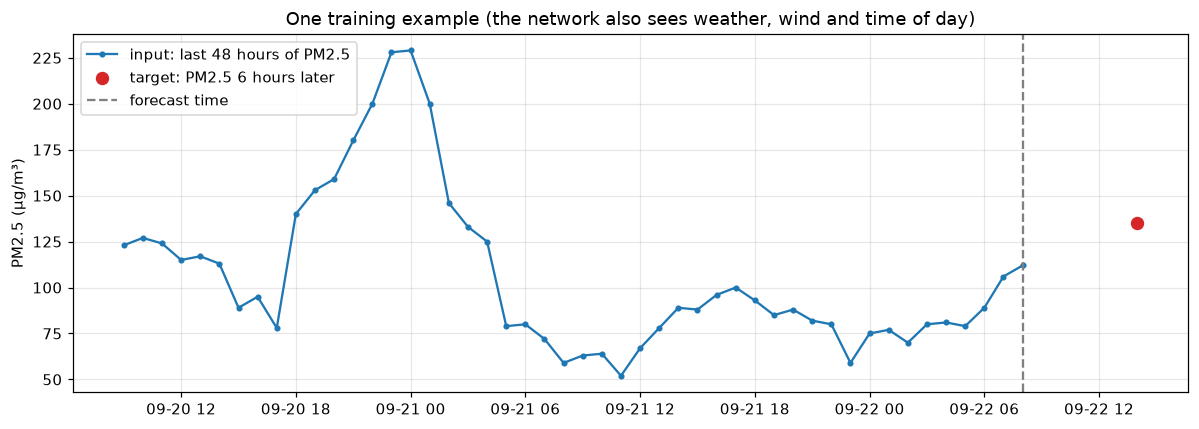

In [5]:
# One example: the 48 hours the network sees, and the value it must forecast
row = 2000
window_end = test.index[row]
history = features.loc[window_end - pd.Timedelta(hours=config.SEQ_LEN - 1):window_end, "pm25"]
target_time = window_end + pd.Timedelta(hours=config.HORIZON)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(history.index, history.values, color="tab:blue", marker=".", label="input: last 48 hours of PM2.5")
ax.scatter([target_time], [test["target"].iloc[row]], color="tab:red", zorder=3, s=60, label="target: PM2.5 6 hours later")
ax.axvline(window_end, color="gray", linestyle="--", label="forecast time")
ax.set_title("One training example (the network also sees weather, wind and time of day)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/15_sequence_window.png")
plt.show()

**What the networks predict:** not the PM2.5 level itself, but the **change over the next 6 hours**. The forecast is then *current PM2.5 + predicted change*. Persistence is the special case "change = 0", so the network starts from the strong baseline and only has to learn the correction.

## 4. The two networks

In [6]:
from lstm_model import LSTMForecaster
from tcn_model import TCNForecaster

lstm = LSTMForecaster(data["n_features"])
tcn = TCNForecaster(data["n_features"])
print(lstm)
print(tcn)
pd.DataFrame({
    "model": ["LSTM", "Temporal CNN (TCN)"],
    "how it reads the 48 hours": ["hour by hour, keeping a memory", "sliding filters with dilation 1, 2, 4, 8"],
    "trainable parameters": [sum(p.numel() for p in lstm.parameters()), sum(p.numel() for p in tcn.parameters())],
})

LSTMForecaster(
  (lstm): LSTM(16, 64, batch_first=True)
  (output): Linear(in_features=64, out_features=1, bias=True)
)
TCNForecaster(
  (convs): ModuleList(
    (0): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(2,))
    (1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
    (2): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(8,), dilation=(4,))
    (3): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(16,), dilation=(8,))
  )
  (relu): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (output): Linear(in_features=32, out_features=1, bias=True)
)


,model,how it reads the 48 hours,trainable parameters
0,LSTM,"hour by hour, keeping a memory",21057
1,Temporal CNN (TCN),"sliding filters with dilation 1, 2, 4, 8",10913


## 5. One training run with early stopping

In [7]:
from dl_training import train_one_model

histories = {}
for name, model_class in [("LSTM", LSTMForecaster), ("TCN", TCNForecaster)]:
    set_seed(config.RANDOM_SEED)
    model = model_class(data["n_features"])
    histories[name] = train_one_model(model, data)
    print(f"{name}: stopped after {len(histories[name])} epochs, best validation MAE {min(histories[name]):.2f}")

persistence_val_mae = np.abs(data["val_current"] - data["val_actual"]).mean()
print(f"Persistence on the same validation hours: {persistence_val_mae:.2f}")

LSTM: stopped after 8 epochs, best validation MAE 32.23


TCN: stopped after 18 epochs, best validation MAE 31.67
Persistence on the same validation hours: 37.16


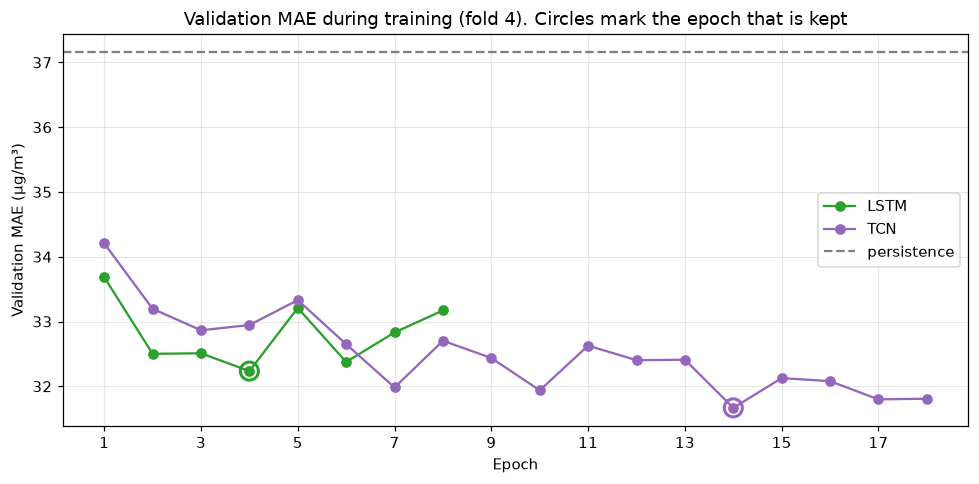

In [8]:
history_table = pd.DataFrame({name: pd.Series(values) for name, values in histories.items()})
history_table.index = history_table.index + 1
history_table.index.name = "epoch"
history_table.round(2).to_csv(f"{OUT}/02_training_history.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, color in [("LSTM", "tab:green"), ("TCN", "tab:purple")]:
    values = histories[name]
    ax.plot(range(1, len(values) + 1), values, marker="o", color=color, label=name)
    best = int(np.argmin(values))
    ax.scatter([best + 1], [values[best]], color=color, s=140, facecolors="none", linewidths=2)
ax.axhline(persistence_val_mae, color="gray", linestyle="--", label="persistence")
ax.set_title("Validation MAE during training (fold 4). Circles mark the epoch that is kept")
ax.set_xlabel("Epoch")
ax.set_xticks(range(1, max(len(v) for v in histories.values()) + 1, 2))
ax.set_ylabel("Validation MAE (µg/m³)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/16_training_curves.png")
plt.show()

## Summary

- Each sample is a **48-hour window of 16 raw features**; no hand-made lags.
- The split is always by time: learn → validate → test. Scaling uses training rows only.
- The networks learn the **6-hour change** in PM2.5 with an L1 (MAE) loss.
- **Early stopping** keeps the weights from the best validation epoch, which prevents overfitting.
- Both networks beat persistence on the validation period after the first epoch.